In [ ]:
import sys
import torch
import matplotlib.pyplot as plt
from pathlib import Path
from torch.utils.data import DataLoader, random_split
from torchvision import transforms
import torch.nn as nn
from torchvision.models import efficientnet_b0, EfficientNet_B0_Weights
import torch.optim as optim
from tqdm import tqdm
import torch.cuda.amp as amp

# Append parent directory to path to import your custom module
sys.path.append(str(Path("..").resolve()))
from scripts.preprocess import DocumentDataset

# Hardware routing (Uses CUDA if you have a local Nvidia GPU, otherwise fallback to CPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Compute Device: {device}")

# Path setup
DATA_DIR = Path("../data").resolve()
TRAIN_CSV = DATA_DIR / "train.csv"

# Note: Depending on how your zip extracted, the 'filename' column (e.g., 'train/invoice/001.tif')
# might need to be appended to DATA_DIR or DATA_DIR / "train"
IMG_ROOT = DATA_DIR / "train"

Compute Device: cpu


In [ ]:
# Standard ImageNet normalization parameters
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# Initialize the custom dataset
full_dataset = DocumentDataset(csv_file=TRAIN_CSV, data_dir=IMG_ROOT, transform=transform)
print(f"Total valid images loaded: {len(full_dataset)}")

# Split 80/20 for Train and Validation
train_size = int(0.8 * len(full_dataset))
val_size = len(full_dataset) - train_size
train_dataset, val_dataset = random_split(full_dataset, [train_size, val_size])

# Initialize DataLoaders
# Dynamically check for a GPU to toggle pin_memory
use_pin_memory = torch.cuda.is_available()

# Initialize DataLoaders with the dynamic flag
train_loader = DataLoader(train_dataset, batch_size=16, shuffle=True, num_workers=4, pin_memory=use_pin_memory)
val_loader = DataLoader(val_dataset, batch_size=16, shuffle=False, num_workers=4, pin_memory=use_pin_memory)

print(f"Training batches: {len(train_loader)}")
print(f"Validation batches: {len(val_loader)}")

Total valid images loaded: 32002
Training batches: 1601
Validation batches: 401


Batch Image Tensor Shape: torch.Size([16, 3, 224, 224])
Batch Label Tensor Shape: torch.Size([16])


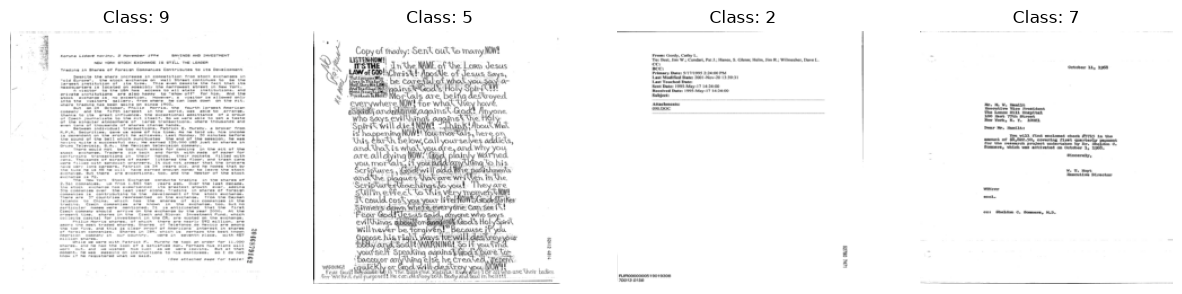

In [ ]:
# Grab one batch
images, labels = next(iter(train_loader))

print(f"Batch Image Tensor Shape: {images.shape}") # Should be [16, 3, 224, 224]
print(f"Batch Label Tensor Shape: {labels.shape}") # Should be [16]

# Visualize the first 4 images in the batch (denormalize first for viewing)
def denormalize(tensor):
    tensor = tensor * torch.tensor([0.229, 0.224, 0.225]).view(3, 1, 1)
    tensor = tensor + torch.tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
    return tensor.clamp(0, 1)

fig, axes = plt.subplots(1, 4, figsize=(15, 5))
for i in range(4):
    img = denormalize(images[i]).permute(1, 2, 0)
    axes[i].imshow(img)
    axes[i].set_title(f"Class: {labels[i].item()}")
    axes[i].axis("off")
plt.show()

In [ ]:
# Load pre-trained weights for faster convergence
weights = EfficientNet_B0_Weights.DEFAULT
model = efficientnet_b0(weights=weights)

# Freeze early layers to retain fundamental edge/texture detection
for param in model.features[:5].parameters():
    param.requires_grad = False

# Reconfigure the final classifier for 16 document classes
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, 16)

model = model.to(device)
print(f"Model loaded and moved to: {device}")

Model loaded and moved to: cpu


In [ ]:
# Setup Model Directory (menyasar "root/models/")
MODEL_DIR = Path("..").resolve() / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Tentukan jumlah class (Sesuaikan dengan dataset-mu)
NUM_CLASSES = 16

label_map = {
    0: "advertisement",
    1: "budget",
    2: "email",
    3: "file_folder",
    4: "form",
    5: "handwritten",
    6: "invoice",
    7: "letter",
    8: "memo",
    9: "news_article",
    10: "presentation",
    11: "questionnaire",
    12: "resume",
    13: "scientific_publication",
    14: "scientific_report",
    15: "specification"
}

# Load pre-trained EfficientNet-B0
model = efficientnet_b0(weights=EfficientNet_B0_Weights.DEFAULT)

# Modifikasi layer klasifikasi terakhir agar sesuai dengan jumlah class kita
in_features = model.classifier[1].in_features
model.classifier[1] = nn.Linear(in_features, NUM_CLASSES)
model = model.to(device)

# Loss function dan Optimizer
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# FIX WARNING: Menggunakan torch.amp.GradScaler sesuai standar PyTorch terbaru
scaler = torch.amp.GradScaler('cuda', enabled=torch.cuda.is_available())

print(f"Model siap! Direktori export: {MODEL_DIR}")

Model siap! Direktori export: D:\Semester 5\SD4504_SML\Document-Image-Classification\models


In [ ]:
CHECKPOINT_PATH = MODEL_DIR / "latest_checkpoint.pth"
BEST_MODEL_PATH = MODEL_DIR / "best_model.pth"

# Parameter kontrol
EPOCHS_TO_RUN_NOW = 1  # Jalankan 1 epoch saja per eksekusi cell
TOTAL_TARGET_EPOCHS = 10

# Inisialisasi awal
start_epoch = 0
best_val_loss = float('inf')

# Load Checkpoint jika ada
if CHECKPOINT_PATH.exists():
    checkpoint = torch.load(CHECKPOINT_PATH, weights_only=False)
    model.load_state_dict(checkpoint['model_state_dict'])
    optimizer.load_state_dict(checkpoint['optimizer_state_dict'])
    scaler.load_state_dict(checkpoint['scaler_state_dict'])
    start_epoch = checkpoint['epoch'] + 1
    best_val_loss = checkpoint['best_val_loss']
    print(f"[INFO] Resume training dari Epoch {start_epoch + 1}...")
else:
    print("[INFO] Memulai training dari nol (Epoch 1)...")

target_epoch = start_epoch + EPOCHS_TO_RUN_NOW

if start_epoch >= TOTAL_TARGET_EPOCHS:
    print("Training sudah mencapai target maksimal (10 Epochs).")
else:
    for epoch in range(start_epoch, target_epoch):
        print(f"\nEpoch {epoch+1}/{TOTAL_TARGET_EPOCHS}")

        # --- TRAINING PHASE ---
        model.train()
        train_loss = 0.0
        correct_train = 0
        total_train = 0

        train_bar = tqdm(train_loader, desc="Training", leave=False)
        for images, labels in train_bar:
            images, labels = images.to(device), labels.to(device)

            optimizer.zero_grad()
            with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
                outputs = model(images)
                loss = criterion(outputs, labels)

            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()

            train_loss += loss.item() * images.size(0)
            _, predicted = torch.max(outputs, 1)
            total_train += labels.size(0)
            correct_train += (predicted == labels).sum().item()
            train_bar.set_postfix({'loss': f"{loss.item():.4f}"})

        epoch_train_loss = train_loss / total_train
        epoch_train_acc = correct_train / total_train

        # --- VALIDATION PHASE ---
        model.eval()
        val_loss = 0.0
        correct_val = 0
        total_val = 0

        val_bar = tqdm(val_loader, desc="Validation", leave=False)
        with torch.no_grad():
            for images, labels in val_bar:
                images, labels = images.to(device), labels.to(device)
                with torch.autocast(device_type=device.type, enabled=torch.cuda.is_available()):
                    outputs = model(images)
                    loss = criterion(outputs, labels)

                val_loss += loss.item() * images.size(0)
                _, predicted = torch.max(outputs, 1)
                total_val += labels.size(0)
                correct_val += (predicted == labels).sum().item()

        epoch_val_loss = val_loss / total_val
        epoch_val_acc = correct_val / total_val

        print(f"Train Loss: {epoch_train_loss:.4f} | Train Acc: {epoch_train_acc:.4f}")
        print(f"Val Loss:   {epoch_val_loss:.4f} | Val Acc:   {epoch_val_acc:.4f}")

        # --- SAVE CHECKPOINT (STATE LENGKAP) ---
        checkpoint_state = {
            'epoch': epoch,
            'model_state_dict': model.state_dict(),
            'optimizer_state_dict': optimizer.state_dict(),
            'scaler_state_dict': scaler.state_dict(),
            'best_val_loss': best_val_loss
        }
        torch.save(checkpoint_state, CHECKPOINT_PATH)
        print(f"Checkpoint disimpan di {CHECKPOINT_PATH} (Bisa di-pause/stop aman).")

        # --- SAVE BEST MODEL ---
        if epoch_val_loss < best_val_loss:
            best_val_loss = epoch_val_loss
            checkpoint_state['best_val_loss'] = best_val_loss
            torch.save(checkpoint_state, BEST_MODEL_PATH)
            torch.save(checkpoint_state, CHECKPOINT_PATH) # Update best_val_loss di latest config
            print(f"--> Valid loss menurun! Best model diperbarui.")

[INFO] Resume training dari Epoch 3...

Epoch 3/10


Train Loss: 0.6337 | Train Acc: 0.8081
Val Loss:   0.6810 | Val Acc:   0.8016
Checkpoint disimpan di D:\Semester 5\SD4504_SML\Document-Image-Classification\models\latest_checkpoint.pth (Bisa di-pause/stop aman).
--> Valid loss menurun! Best model diperbarui.
